# 01 · From MaleCNS to detailed balance

**The Stochastic Fly · Research assignment**

**Research question.** When can spontaneous fluctuations in a stochastic neural network predict its response to a small external field? The fluctuation–dissipation relation gives us an equilibrium prediction. To use that prediction as a benchmark, we first need to build an equilibrium reference and check that our implementation actually has detailed balance.

This notebook takes you from an anatomical contact table to an exact finite-state experiment. You will build a coupling matrix, specify a random-sequential dynamics, and measure the stationary probability currents. You will work with a synthetic fixture for debugging and a three-cell example drawn from MaleCNS v1.0. All experimental computations are yours.

### How to work through the notebook

1. Run the two **provided setup** cells. Study the prose before each exercise, then implement its Python cell from scratch.
2. Run your functions on the synthetic fixture before applying them to the MaleCNS data. Each exercise gives output names or function signatures so you can connect your work across cells.
3. Write your explanations in the Markdown cells marked **Your answer**. Keep the prompts and the outputs when you submit the notebook for review.

No background in connectomics is assumed. You will use Python functions and loops, NumPy arrays and matrix multiplication, and basic pandas filtering and grouping. Review conditional probability, matrix transposition, and linear systems as you encounter them. There is no optimization or training in this assignment. A later notebook will introduce the field-step response and its prediction from spontaneous covariance.

## Provided setup A · Imports, parameters, and a fixture

The synthetic fixture is a small artificial contact table. We retain cells 101, 102, and 103. Cell 104 is an annotated source outside the retained graph. That extra source lets you test whether the normalization accounts for inputs that are omitted from the dynamics. Two rows record the same directed pair so that you can test aggregation before a nonlinear transformation. All four cell IDs are arbitrary labels.

The parameters below give a moderate regime for debugging. They belong to the mathematical model and have no physical units in this notebook. `RTOL` is a floating-point comparison tolerance. Use your own smaller or larger β only after the default checks pass.

In [1]:
from itertools import product
import os
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.ipc as ipc

DATA_DIR_OVERRIDE = None  # Example: Path(r"D:\datasets\MaleCNS")
BETA = 2.0
GAIN = 1.0
THRESHOLD = 0.35
REST_FIELD = 0.0
ALPHAS = np.linspace(0.0, 1.0, 11)
ATOL = 1e-12
RTOL = 1e-9

SIGN_BY_TRANSMITTER = {
    "acetylcholine": +1,
    "gaba": -1,
    "histamine": -1,
    "glutamate": -1,
}

TOY_IDS = (101, 102, 103)
toy_cells = pd.DataFrame(
    {"consensus_nt": ["acetylcholine", "gaba", "dopamine", "acetylcholine"]},
    index=pd.Index([101, 102, 103, 104], name="bodyId"),
)
toy_contacts = pd.DataFrame(
    [
        (101, 102, 4),
        (101, 102, 2),
        (102, 101, 2),
        (103, 102, 9),
        (104, 101, 6),
        (101, 101, 15),
    ],
    columns=["body_pre", "body_post", "weight"],
)
display(toy_contacts)

,body_pre,body_post,weight
0,101,102,4
1,101,102,2
2,102,101,2
3,103,102,9
4,104,101,6
5,101,101,15


## Provided setup B · Load the MaleCNS inputs for a small circuit

MaleCNS reconstructs one adult male fruit fly's central nervous system from electron microscopy. The project aligns images, segments cells, identifies putative chemical synaptic contacts, and proofreads the reconstructed neurons. The release separates cell annotations, transmitter assignments, and directed connection counts into three Feather files. Here `body_pre` is the presynaptic source, `body_post` is the postsynaptic target, and `weight` counts the contacts in that record. The Feather table is a graph of reconstructed segments, so this assignment uses cells whose annotation has `status == "Traced"` as its modeling universe. This is an explicit release-table filter, and its count can differ from the headline neuron count in the paper. [Berg et al., MaleCNS reconstruction and STAR Methods](https://api.repository.cam.ac.uk/server/api/core/bitstreams/014024cf-3435-4a89-a5ed-bc34e2385772/content) · [MaleCNS v1.0 data release](https://male-cns.janelia.org/download/)

We use two visual LPLC2 cells and a descending DNp01 cell as a concrete set of body IDs. LPLC2 and DNp01 have a documented relationship in a visual escape pathway. Here the subset is a computational example for studying a few matrix entries; its dynamics is defined only on the selected cells. [Ache et al. (2019)](https://doi.org/10.1016/j.cub.2019.01.079)

The supplied code scans the approximately 1 GB connection file in Arrow batches and keeps incoming rows for just these targets, including rows from other traced sources **outside** the three cells. You need the outside sources to recover the full incoming denominators. The scan may take a moment on a cold disk cache. It reads your existing data files in place. If the data are in a different directory, set `DATA_DIR_OVERRIDE` in the first setup cell. You can complete the synthetic portion while arranging access to the MaleCNS files.

In [2]:
MALECNS_IDS = (31563, 22253, 10010)  # LPLC2, LPLC2, DNp01
ANNOTATION_FILE = "body-annotations-male-cns-v1.0-minconf-0.5.feather"
TRANSMITTER_FILE = "body-neurotransmitters-male-cns-v1.0.feather"
CONNECTION_FILE = "connectome-weights-male-cns-v1.0-minconf-0.5.feather"
REQUIRED_FILES = (ANNOTATION_FILE, TRANSMITTER_FILE, CONNECTION_FILE)

override = DATA_DIR_OVERRIDE or os.environ.get("MALECNS_DATA_DIR")
if override:
    candidates = (Path(override).expanduser(),)
else:
    cwd = Path.cwd()
    candidates = tuple(
        path
        for folder in (cwd, *cwd.parents)
        for path in (folder / "data", folder / "repo_malecns_legacy" / "data")
    )

data_dir = next(
    (path for path in candidates if all((path / name).is_file() for name in REQUIRED_FILES)),
    None,
)
if data_dir is None:
    raise FileNotFoundError(
        "Set DATA_DIR_OVERRIDE or MALECNS_DATA_DIR to the directory that contains "
        "all three MaleCNS v1.0 Feather files."
    )

annotations = pd.read_feather(
    data_dir / ANNOTATION_FILE,
    columns=["bodyId", "status", "type", "superclass"],
)
traced_cells = annotations.loc[annotations["status"].eq("Traced")].set_index("bodyId")
transmitters = pd.read_feather(
    data_dir / TRANSMITTER_FILE,
    columns=["body", "consensus_nt"],
).set_index("body")
malecns_cells = traced_cells.join(transmitters, validate="one_to_one")

missing_ids = set(MALECNS_IDS) - set(malecns_cells.index)
if missing_ids:
    raise ValueError(f"Expected MaleCNS v1.0 traced cells are missing: {sorted(missing_ids)}")

incoming_batches = []
with pa.memory_map(str(data_dir / CONNECTION_FILE), "r") as source:
    reader = ipc.open_file(source)
    for batch_index in range(reader.num_record_batches):
        batch = reader.get_batch(batch_index)
        target = batch.column("body_post").to_numpy()
        keep = np.isin(target, MALECNS_IDS)
        if keep.any():
            incoming_batches.append(
                pd.DataFrame({
                    "body_pre": batch.column("body_pre").to_numpy()[keep],
                    "body_post": target[keep],
                    "weight": batch.column("weight").to_numpy()[keep],
                })
            )

if not incoming_batches:
    raise ValueError("The connection file has no incoming rows for the selected body IDs.")

incoming_rows = pd.concat(incoming_batches, ignore_index=True)
malecns_contacts = incoming_rows.loc[
    incoming_rows["body_pre"].isin(malecns_cells.index) & incoming_rows["weight"].gt(0)
].reset_index(drop=True)

print("Loaded MaleCNS v1.0 from the local Feather files.")
print(f"Traced cells in the annotation table: {len(malecns_cells):,}")
print(f"Incoming contact rows from traced cells: {len(malecns_contacts):,}")
display(malecns_cells.loc[list(MALECNS_IDS)])
display(malecns_contacts.head())

Loaded MaleCNS v1.0 from the local Feather files.
Traced cells in the annotation table: 165,122
Incoming contact rows from traced cells: 1,900


,status,type,superclass,consensus_nt
bodyId,,,,
31563,Traced,LPLC2,visual_projection,acetylcholine
22253,Traced,LPLC2,visual_projection,acetylcholine
10010,Traced,DNp01,descending_neuron,acetylcholine


,body_pre,body_post,weight
0,10580,10010,739
1,10074,10010,414
2,11927,10010,258
3,10263,10010,258
4,15791,10010,237


## 1 · Audit the anatomical inputs

A **directed edge** goes from the source $j$ to the target $i$. An edge count summarizes detected contacts. Multiple rows for an ordered pair, if present, must be summed before converting the count into a coupling. A reverse edge is a separate ordered pair. It may have a different count or be absent. A body ID identifies a reconstructed cell and can be much larger than the size of our matrix.

**Exercise 1.** For each fixture, make a table of the selected cells in the order given by `TOY_IDS` or `MALECNS_IDS`. Then:

1. Group incoming records by ordered pair and report the number of distinct pairs, the sum of their contact counts, and how many pairs are internal to the selected cells. Label all three quantities. Keep autapses in this audit and explicitly report how many there are.
2. Print the internal off-diagonal pairs and their counts. For each LPLC2 → DNp01 direction represented in the sample, check the reverse direction in the same table. When a pair is absent, give its missing count as zero in this release.
3. Count how much of each target's incoming contact count is captured by the small circuit before adding signs or transforming magnitudes. Explain why that fraction can differ from the fraction of **effective** incoming strength you will calculate in Exercise 2.

**Python starting points.** `DataFrame.loc` selects rows, `Series.isin` builds a membership mask, and `groupby` with `sum` aggregates records. A small pivot table is useful after filtering both endpoints. Leave the full connection table in Feather format.

In [4]:
def audit_inputs(contacts, cells, selected_ids):
    """Summarize the anatomical inputs to the selected cells."""

    # Keep the selected neurons in the order specified by selected_ids.
    selected = cells.loc[list(selected_ids)]
    print("Selected cells")
    display(selected)

    # Combine records for the same directed pair.
    # Grouping by both columns keeps A → B separate from B → A.
    pairs = (
        contacts.groupby(["body_pre", "body_post"], as_index=False)["weight"]
        .sum()
    )

    # An internal pair has both endpoints in the selected set.
    # An autapse has the same source and target.
    source_is_selected = pairs["body_pre"].isin(selected_ids)
    target_is_selected = pairs["body_post"].isin(selected_ids)
    is_internal = source_is_selected & target_is_selected
    is_autapse = pairs["body_pre"].eq(pairs["body_post"])

    print(f"Distinct directed pairs: {len(pairs)}")
    print(f"Total contact count: {pairs['weight'].sum()}")
    print(f"Internal directed pairs, including autapses: {is_internal.sum()}")
    print(f"Autapses: {is_autapse.sum()}")

    # Exclude self-connections from this display only.
    print("Internal off-diagonal pairs")
    display(pairs.loc[is_internal & ~is_autapse])

    # Group by the target because coverage is an incoming quantity.
    # The denominator includes all sources in the supplied contact table.
    total_incoming = pairs.groupby("body_post")["weight"].sum()
    internal_incoming = (
        pairs.loc[is_internal].groupby("body_post")["weight"].sum()
    )

    # Reindex so that targets with no incoming contacts still appear.
    coverage = pd.DataFrame(index=selected.index)
    coverage["total_incoming"] = total_incoming.reindex(
        selected.index, fill_value=0
    )
    coverage["internal_incoming"] = internal_incoming.reindex(
        selected.index, fill_value=0
    )

    # A target with zero total incoming contacts has undefined coverage.
    denominator = coverage["total_incoming"].where(
        coverage["total_incoming"].gt(0)
    )
    coverage["raw_coverage"] = coverage["internal_incoming"] / denominator

    print("Incoming contact coverage, including autapses")
    display(coverage)

    return pairs


print("=== Synthetic fixture ===")
toy_pairs = audit_inputs(toy_contacts, toy_cells, TOY_IDS)

print("\n=== MaleCNS ===")
malecns_pairs = audit_inputs(malecns_contacts, malecns_cells, MALECNS_IDS)

# Identify the LPLC2 and DNp01 cells among the selected MaleCNS neurons.
selected_types = malecns_cells.loc[list(MALECNS_IDS), "type"]
lplc2_ids = selected_types.loc[selected_types.eq("LPLC2")].index
dnp01_ids = selected_types.loc[selected_types.eq("DNp01")].index

# Index counts by (source, target) so each direction can be looked up.
# After aggregation, each ordered pair has at most one entry.
count_by_pair = malecns_pairs.set_index(["body_pre", "body_post"])["weight"]

reverse_checks = []
for visual_id in lplc2_ids:
    for descending_id in dnp01_ids:
        forward_count = count_by_pair.get((visual_id, descending_id), 0)
        reverse_count = count_by_pair.get((descending_id, visual_id), 0)

        reverse_checks.append({
            "LPLC2_body_id": visual_id,
            "DNp01_body_id": descending_id,
            "LPLC2_to_DNp01": forward_count,
            "DNp01_to_LPLC2": reverse_count,
        })

print("MaleCNS contact counts in both directions")
display(pd.DataFrame(reverse_checks))

=== Synthetic fixture ===
Selected cells


,consensus_nt
bodyId,
101,acetylcholine
102,gaba
103,dopamine


Distinct directed pairs: 5
Total contact count: 38
Internal directed pairs, including autapses: 4
Autapses: 1
Internal off-diagonal pairs


,body_pre,body_post,weight
1,101,102,6
2,102,101,2
3,103,102,9


Incoming contact coverage, including autapses


,total_incoming,internal_incoming,raw_coverage
bodyId,,,
101,23,17,0.73913
102,15,15,1.00000
103,0,0,NaN


... (4 outputs left out)

Incoming contact coverage, including autapses


,total_incoming,internal_incoming,raw_coverage
bodyId,,,
31563,1718,5,0.002910
22253,2309,4,0.001732
10010,20684,124,0.005995


MaleCNS contact counts in both directions


,LPLC2_body_id,DNp01_body_id,LPLC2_to_DNp01,DNp01_to_LPLC2
0,31563,10010,64,0
1,22253,10010,60,1


## 2 · Build $J$ from $c$

Let $V$ be the modeled universe of traced cells and $U\subset V$ the subset retained for a calculation. In the fixture, $V$ is the four artificial cells. Use $c_{ji}$ for the total count from $j$ to $i$. The NumPy array `C` and the coupling matrix `J` both have **target rows and source columns**. Thus `C[i, j]` stores $c_{ji}$ in the chosen subset ordering, and `J @ sigma` gives a vector of recurrent inputs.

For each presynaptic cell $j$, use a sign $a_j$ from its consensus neurotransmitter annotation. An acetylcholine label gives $+1$ and GABA, histamine and glutamate give $-1$ in the baseline. Unresolved and unmodeled labels give zero. This is an effective model assumption, particularly for glutamate. Receptor identity and cellular context also matter. The sign acts on the **source**. [Berg et al., STAR Methods](https://api.repository.cam.ac.uk/server/api/core/bitstreams/014024cf-3435-4a89-a5ed-bc34e2385772/content) · [Eckstein et al. (2024)](https://doi.org/10.1016/j.cell.2024.03.016)

Choose a nonnegative magnitude transform $f$ with $f(0)=0$. Start with $f(c)=c$. For example, $f(c)=\log(1+c)$ compresses large counts and must be applied to the pair total. The unnormalized coupling has zero diagonal. For the other entries,
$$
w_{ij}=a_j f(c_{ji}),\qquad Z_i=\sum_{k\in V:\,k\ne i}|a_k f(c_{ki})|,\qquad
J_{ij}^{(U)}=\frac{w_{ij}}{Z_i}\quad (i,j\in U,\ Z_i>0).
$$
Rows with $Z_i=0$ are zero. We remove autapses before calculating $Z_i$. Restricting to $U$ after this normalization preserves the weight of each retained edge. Summing only over $U$ when computing $Z_i$ would inflate weights for cells with omitted inputs. The quantity $\sum_{j\in U}|J_{ij}^{(U)}|$ is the retained fraction of effective incoming strength when $Z_i>0$. It lies in $[0,1]$.

**Exercise 2.** Define `build_weights(contacts, cells, selected_ids, sign_map, transform)` returning `C, J, Z`.

1. Aggregate repeated ordered pairs. Build `C` as an integer matrix of internal counts, with the diagonal kept for annotation audit. Then exclude self-edges from the effective model.
2. Use `cells["consensus_nt"]` to attach the sign to the source. Treat missing or unmapped labels as zero. Calculate `Z` with **all** eligible incoming sources found in the supplied table. Only then form the restricted `J`. Use a signed floating-point dtype for weights and preserve the supplied ID order.
3. Produce `C_toy, J_toy, Z_toy` and `C_malecns, J_malecns, Z_malecns` for the identity transform. Show the labeled internal contact and coupling matrices and a table of $Z_i$ and retained absolute incoming strength. Run the function again with `np.log1p` on the synthetic fixture to verify the order of aggregation.
4. Add checks for square shapes, zero diagonal in `J`, finite values, and absolute row sums at most one within tolerance. Check a positive, a negative, and a zero coupling by hand from the fixture. Include a check that the zero-denominator row stays zero. Explain why the synthetic autapse can change the audit but cannot affect the dynamics, and why cell 104 can affect `Z` even though it has no column in `J`.

**Python starting points.** A mapping from body ID to position avoids confusing IDs with row offsets. Use `np.zeros` and an explicit loop if that is clearest. For division by a vector of row scales, think about what axis aligns with the targets. A short loop over three rows is fine.

In [5]:
def build_weights(contacts, cells, selected_ids, sign_map, transform):
    """Return the internal contact matrix C, coupling matrix J, and input scales Z."""
    ids = list(selected_ids)

    # Aggregate before applying f. For example, records with 4 and 2
    # contacts for one pair become a single count of 6.
    pairs = (
        contacts.groupby(["body_pre", "body_post"], as_index=False)["weight"]
        .sum()
    )

    # Build the raw contact matrix for the selected cells.
    # Rows are targets, columns are sources. Missing pairs have count zero.
    is_internal = pairs["body_pre"].isin(ids) & pairs["body_post"].isin(ids)
    C = (
        pairs.loc[is_internal]
        .pivot(index="body_post", columns="body_pre", values="weight")
        .reindex(index=ids, columns=ids)
        .fillna(0)
        .to_numpy(dtype=np.int64)
    )

    # Assign one effective sign to each SOURCE cell.
    # Transmitters outside the sign map, including missing labels, map to zero.
    sign_by_body = cells["consensus_nt"].map(sign_map).fillna(0)

    # For Z, keep all incoming sources, including those outside the subset.
    # Remove autapses before computing any effective weights.
    incoming = pairs.loc[
        pairs["body_post"].isin(ids) & pairs["body_pre"].ne(pairs["body_post"])
    ]
    incoming_signs = (
        incoming["body_pre"].map(sign_by_body).fillna(0).to_numpy(dtype=float)
    )
    incoming_counts = incoming["weight"].to_numpy(dtype=float)
    absolute_weights = np.abs(incoming_signs * transform(incoming_counts))

    # Sum absolute effective weights by TARGET, then align with C's row order.
    Z = (
        pd.Series(absolute_weights, index=incoming["body_post"], dtype=float)
        .groupby(level=0)
        .sum()
        .reindex(ids, fill_value=0)
        .to_numpy()
    )

    # Construct signed weights for the retained pairs.
    # source_signs[None, :] applies the sign to each source COLUMN.
    source_signs = sign_by_body.reindex(ids, fill_value=0).to_numpy(dtype=float)
    W = transform(C.astype(float)) * source_signs[None, :]
    np.fill_diagonal(W, 0.0)

    # Divide target row i by Z[i]. Starting from zeros preserves the
    # zero row whenever a target has no effective incoming strength.
    J = np.zeros_like(W)
    np.divide(W, Z[:, None], out=J, where=Z[:, None] > 0)

    return C, J, Z


def identity(counts):
    """Use the contact count itself as the baseline magnitude."""
    return counts


C_toy, J_toy, Z_toy = build_weights(
    toy_contacts, toy_cells, TOY_IDS, SIGN_BY_TRANSMITTER, identity
)

C_malecns, J_malecns, Z_malecns = build_weights(
    malecns_contacts, malecns_cells, MALECNS_IDS, SIGN_BY_TRANSMITTER, identity
)

for name, ids, C, J, Z in [
    ("Synthetic fixture", TOY_IDS, C_toy, J_toy, Z_toy),
    ("MaleCNS", MALECNS_IDS, C_malecns, J_malecns, Z_malecns),
]:
    # The absolute row sum is the retained share of the input strength
    # whenever Z is positive.
    retained_strength = np.abs(J).sum(axis=1)

    assert C.shape == J.shape == (len(ids), len(ids))
    assert Z.shape == (len(ids),)
    assert np.isfinite(J).all() and np.isfinite(Z).all()
    assert (Z >= 0).all()
    np.testing.assert_allclose(np.diag(J), 0, atol=ATOL)
    assert np.all(retained_strength <= 1 + ATOL)
    assert np.all(J[Z == 0] == 0)

    target_ids = pd.Index(ids, name="target")
    source_ids = pd.Index(ids, name="source")

    print(f"\n{name} · raw contact counts C")
    display(pd.DataFrame(C, index=target_ids, columns=source_ids))

    print(f"{name} · normalized couplings J")
    display(pd.DataFrame(J, index=target_ids, columns=source_ids).round(6))

    print(f"{name} · incoming normalization")
    display(pd.DataFrame({
        "Z_full": Z,
        "retained_absolute_row_sum": retained_strength,
    }, index=target_ids))


# Check one positive, one negative, and one zero coupling by hand.
# The toy matrix uses the order (101, 102, 103).
np.testing.assert_allclose(Z_toy, [8, 6, 0], atol=ATOL, rtol=RTOL)
np.testing.assert_allclose(J_toy[1, 0], 1.0, atol=ATOL)    # 101 → 102
np.testing.assert_allclose(J_toy[0, 1], -0.25, atol=ATOL)  # 102 → 101
np.testing.assert_allclose(J_toy[1, 2], 0.0, atol=ATOL)    # 103 → 102
assert C_toy[0, 0] == 15 and J_toy[0, 0] == 0             # autapse at 101

# Check the order of operations with a nonlinear transform.
# Target 102 gets effective input only from 101, with 4 + 2 contacts.
# Checking Z is important because J[1, 0] is 1 after either normalization.
_, _, Z_toy_log = build_weights(
    toy_contacts, toy_cells, TOY_IDS, SIGN_BY_TRANSMITTER, np.log1p
)
np.testing.assert_allclose(Z_toy_log[1], np.log1p(6), atol=ATOL, rtol=RTOL)

print("Synthetic fixture checks passed.")


Synthetic fixture · raw contact counts C


source,101,102,103
target,,,
101,15,2,0
102,6,0,9
103,0,0,0


Synthetic fixture · normalized couplings J


source,101,102,103
target,,,
101,0.0,-0.25,0.0
102,1.0,0.00,0.0
103,0.0,0.00,0.0


Synthetic fixture · incoming normalization


,Z_full,retained_absolute_row_sum
target,,
101,8.0,0.25
102,6.0,1.00
103,0.0,0.00


... (3 outputs left out)

source,31563,22253,10010
target,,,
31563,0.000000,0.002926,0.000000
22253,0.001305,0.000000,0.000435
10010,0.003105,0.002911,0.000000


MaleCNS · incoming normalization


,Z_full,retained_absolute_row_sum
target,,
31563,1709.0,0.002926
22253,2299.0,0.001740
10010,20612.0,0.006016


Synthetic fixture checks passed.


## 3 · Turn a binary neural network into a Markov chain

McCulloch and Pitts model a neuron by a binary output and a threshold rule. In the stochastic version a selected cell is assigned state 1 with a probability that depends smoothly on its local field. The state $\sigma_i=1$ represents activity in the model. The full configuration $\sigma$ is a vector of zeros and ones. We write $\sigma(t)$ for the full configuration at time $t$, and $\sigma_i(t)$ for the state of cell $i$ at that time. With a constant $h$ this produces a time-homogeneous Markov chain, because only the current configuration is needed for the next update. [McCulloch & Pitts (1943)](https://doi.org/10.1007/BF02478259) · [Levin & Peres, §3.3.2](https://pages.uoregon.edu/dlevin/MARKOV/markovmixing.pdf)

The course also uses spins in $\{-1,+1\}$. Here $\sigma_i$ encodes activity in $\{0,1\}$, and the corresponding spin is $s_i=2\sigma_i-1$. In the same field, the activation probability is $\tfrac12[1+\tanh(\beta\phi_i/2)]$. To write the field entirely in spin coordinates, substitute $\sigma_j=(s_j+1)/2$ into its definition. The term $h_i-\theta_i$ is the external field minus the threshold.

$$
\phi_i(\sigma)=g(J\sigma)_i+h_i-\theta_i,\qquad
q_i(\sigma)=\Pr(\sigma_i'=1\mid \sigma,\ \text{site }i\text{ chosen})=\frac{1}{1+\exp[-\beta\phi_i(\sigma)]}.
$$

- $g$ scales the recurrent input, $h_i$ is the external field, and $\theta_i$ is the threshold. Here $h$ is fixed at zero, with the same threshold on each cell.
- $\beta$ is the inverse-noise parameter. At $\beta=0$, each selected cell becomes 1 with probability $1/2$. For a positive field, increasing $\beta$ increases this probability. At a zero field the probability is still $1/2$.
- In one **elementary step**, choose one index uniformly and resample that cell from its Bernoulli distribution. The other cells remain unchanged. A resampling that retains the previous value is a valid step.
- One **sweep** is $N$ elementary steps with replacement. The time in this notebook is measured in elementary steps. On this exact chain, $P^N$ would be the transition matrix for one sweep.

The transition matrix uses source configurations as rows and destination configurations as columns. If $\sigma'$ differs from $\sigma$ only at $i$, $P(\sigma,\sigma')$ is the probability $1/N$ of choosing site $i$ times the probability of drawing the new value $\sigma'_i$. To get $P(\sigma,\sigma)$, all sites can contribute, so sum the probability of resampling the current value over every possible chosen site. Configurations at Hamming distance greater than one cannot communicate in a single step. At finite parameters all hypercube neighbors and all self-transitions have positive probability in the mathematical model. The chain is irreducible and aperiodic, hence it has a unique stationary law and converges to it.

**Exercise 3.** Define `state_space(n)` returning an array of shape `(2**n, n)` with deterministic ordering. Define `transition_matrix(J, states, beta, gain, threshold, field)` returning `P`. Accept scalars for the uniform threshold and field used here, or vectors with one element per cell. Use a dictionary from configuration tuples to matrix indices, then enumerate the two possible assignments for each site in each row. Pay attention to whether an entry must be accumulated or assigned.

Run your code on `J_toy` and `J_malecns`. Verify that rows sum to one, entries are nonnegative, the diagonal is positive, and entries joining states more than one flip apart are zero. Independently test $\beta=0$. Work out beforehand what probability a one-bit neighbor and the diagonal should have. Use the fixture's small dimension for this construction. The state space has $2^N$ states and the dense kernel has $4^N$ entries.

**Python starting points.** Use `itertools.product` to enumerate states, make a copy before modifying a candidate destination, and treat the source state as fixed while enumerating its row. The default parameters keep the logistic calculation far from exponential overflow.

In [6]:
def state_space(n):
    """Enumerate all binary configurations in a reproducible order."""
    # For n = 2, product gives (0, 0), (0, 1), (1, 0), (1, 1).
    return np.array(list(product((0, 1), repeat=n)), dtype=np.int8)


def transition_matrix(J, states, beta, gain, threshold, field):
    """Build the transition matrix for one random-sequential update."""
    n_states, n_cells = states.shape

    # Translate a configuration such as (0, 1, 0) into its row or column index.
    state_to_index = {tuple(state): idx for idx, state in enumerate(states)}

    # Rows are source configurations. Columns are destination configurations.
    P = np.zeros((n_states, n_states), dtype=float)

    for row, sigma in enumerate(states):
        # Evaluate the local fields at the original configuration sigma.
        # NumPy broadcasts a scalar field or threshold to all cells.
        phi = gain * (J @ sigma) + field - threshold
        logits = beta * phi

        # These are the probabilities of assigning 0 or 1, conditional
        # on selecting the cell. logaddexp evaluates the logistic stably:
        # exp(-logaddexp(0, -z)) = 1 / (1 + exp(-z)).
        p_one = np.exp(-np.logaddexp(0.0, -logits))
        p_zero = np.exp(-np.logaddexp(0.0, logits))

        for site in range(n_cells):
            # Selecting this site has probability 1/n_cells.
            # All other cells retain their values in sigma.
            sigma_next = sigma.copy()

            for new_value, probability in (
                (0, p_zero[site]),
                (1, p_one[site]),
            ):
                sigma_next[site] = new_value
                col = state_to_index[tuple(sigma_next)]

                # Several choices of site can lead to the same destination.
                # In particular, every site can contribute to P[sigma, sigma].
                P[row, col] += probability / n_cells

    return P


states_toy = state_space(len(TOY_IDS))
states_malecns = state_space(len(MALECNS_IDS))

P_toy = transition_matrix(
    J_toy, states_toy, BETA, GAIN, THRESHOLD, REST_FIELD
)
P_malecns = transition_matrix(
    J_malecns, states_malecns, BETA, GAIN, THRESHOLD, REST_FIELD
)

for name, states, P in [
    ("Synthetic fixture", states_toy, P_toy),
    ("MaleCNS", states_malecns, P_malecns),
]:
    # Compare every pair of configurations and count differing bits.
    hamming_distance = np.count_nonzero(
        states[:, None, :] != states[None, :, :],
        axis=2,
    )

    # Every row is a probability distribution over the next configuration.
    np.testing.assert_allclose(P.sum(axis=1), 1.0, atol=ATOL, rtol=RTOL)
    assert np.all(P >= 0)
    assert np.all(np.diag(P) > 0)

    # A single update can change at most one bit.
    assert np.all(P[hamming_distance > 1] == 0)

    print(f"{name}: transition matrix checks passed.")
    labels = ["".join(str(bit) for bit in state) for state in states]
    display(pd.DataFrame(P, index=labels, columns=labels).round(4))


# Independent check at beta = 0: the selected cell gets a fair draw.
# The probability of staying in sigma is 1/2 after summing over all sites.
# A particular one-bit change requires choosing its site and drawing
# the opposite value, so its probability is 1/(2*n_cells).
P_beta_zero = transition_matrix(
    J_toy, states_toy, 0.0, GAIN, THRESHOLD, REST_FIELD
)

n_cells = states_toy.shape[1]
distance_toy = np.count_nonzero(
    states_toy[:, None, :] != states_toy[None, :, :],
    axis=2,
)

np.testing.assert_allclose(np.diag(P_beta_zero), 0.5, atol=ATOL, rtol=RTOL)
np.testing.assert_allclose(
    P_beta_zero[distance_toy == 1],
    1 / (2 * n_cells),
    atol=ATOL,
    rtol=RTOL,
)
assert np.all(P_beta_zero[distance_toy > 1] == 0)

print("Beta-zero check passed.")

Synthetic fixture: transition matrix checks passed.


,000,001,010,011,100,101,110,111
000,0.6682,0.1106,0.1106,0.0000,0.1106,0.0000,0.0000,0.0000
001,0.2227,0.5561,0.0000,0.1106,0.0000,0.1106,0.0000,0.0000
010,0.2227,0.0000,0.5895,0.1106,0.0000,0.0000,0.0772,0.0000
011,0.0000,0.2227,0.2227,0.4774,0.0000,0.0000,0.0000,0.0772
100,0.2227,0.0000,0.0000,0.0000,0.4047,0.1106,0.2619,0.0000
101,0.0000,0.2227,0.0000,0.0000,0.2227,0.2926,0.0000,0.2619
110,0.0000,0.0000,0.2562,0.0000,0.0714,0.0000,0.5618,0.1106
111,0.0000,0.0000,0.0000,0.2562,0.0000,0.0714,0.2227,0.4497


MaleCNS: transition matrix checks passed.


,000,001,010,011,100,101,110,111
000,0.6682,0.1106,0.1106,0.0000,0.1106,0.0000,0.0000,0.0000
001,0.2227,0.5560,0.0000,0.1107,0.0000,0.1106,0.0000,0.0000
010,0.2227,0.0000,0.5552,0.1110,0.0000,0.0000,0.1110,0.0000
011,0.0000,0.2227,0.2223,0.4440,0.0000,0.0000,0.0000,0.1110
100,0.2227,0.0000,0.0000,0.0000,0.5554,0.1111,0.1108,0.0000
101,0.0000,0.2227,0.0000,0.0000,0.2223,0.4441,0.0000,0.1109
110,0.0000,0.0000,0.2223,0.0000,0.2225,0.0000,0.4437,0.1115
111,0.0000,0.0000,0.0000,0.2223,0.0000,0.2225,0.2218,0.3334


Beta-zero check passed.


## 4 · Find the stationary law and measure probability currents

Write probabilities as row vectors. Stationarity means $\pi P=\pi$ and $\sum_{\sigma}\pi(\sigma)=1$. It says that the total probability of occupying each state is constant in time. Define the stationary flux from $\sigma$ to $\sigma'$ as $F_{\sigma,\sigma'}=\pi(\sigma)P(\sigma,\sigma')$. The net current is the antisymmetric matrix $\mathcal I=F-F^\mathsf T$. Stationarity implies $\sum_{\sigma'}\mathcal I_{\sigma,\sigma'}=0$ for every $\sigma$. Incoming and outgoing flux balance in total, so there may still be a circulation around a loop. **Detailed balance** makes each individual net current zero. [Levin & Peres, §1.6](https://pages.uoregon.edu/dlevin/MARKOV/markovmixing.pdf)

$$
D(P) = \max_{\sigma,\sigma'} |\mathcal I_{\sigma,\sigma'}|.
$$

This is an absolute residual in probability per elementary step. It tests all edges of the finite chain because we have the full kernel here. Comparing its size across conditions is descriptive. A small absolute value can also occur when relevant transitions carry very little probability.

**Exercise 4.** Implement `stationary_distribution(P)`, returning a 1D array `pi`, and `stationary_current(P, pi)`, returning `current`.

1. Solve the linear system defined by $P^\mathsf{T}-\mathrm{Id}$ and replace one equation with the normalization constraint. Start with a system whose right-hand side is zero and set the normalization row's right-hand side to one. Use `np.linalg.solve`.
2. Check that `pi` is nonnegative within numerical tolerance, sums to one, and satisfies `pi @ P == pi` within tolerance. A large negative component or residual indicates a bug. Preserve the residual for diagnosis.
3. Construct the flux and current. Confirm that the current is antisymmetric and its row sums are approximately zero. Print $D(P)$ and the two configurations that give the largest absolute current for each directed fixture. State the direction of the net flow in words.

**Python starting points.** For broadcasting, reshape `pi` to a column so it scales the source rows. Use absolute tolerances for quantities whose theoretical value is zero. To locate a matrix maximum, NumPy can convert the result of `argmax` to a row and column.

In [7]:
def stationary_distribution(P):
    """Find the stationary distribution of a finite irreducible chain."""
    n_states = P.shape[0]

    # We store pi as a row vector, so stationarity is pi @ P = pi.
    # Transpose the equation to put the unknowns in column form.
    system = P.T - np.eye(n_states)
    rhs = np.zeros(n_states)

    # The stationarity equations are linearly dependent.
    # Replace one equation with the constraint that probabilities sum to 1.
    system[-1, :] = 1.0
    rhs[-1] = 1.0

    # The returned 1D array represents the stationary probabilities.
    return np.linalg.solve(system, rhs)


def stationary_current(P, pi):
    """Return the net probability current between every pair of states."""
    # pi[:, None] scales each source row by its stationary probability.
    # flux[source, target] is the joint probability of successive states at stationarity.
    flux = pi[:, None] * P

    # A positive current means more probability flows from source to target
    # than in the reverse direction, per elementary update.
    return flux - flux.T


# Keep both results available for the next exercises.
pi_toy = stationary_distribution(P_toy)
pi_malecns = stationary_distribution(P_malecns)

current_toy = stationary_current(P_toy, pi_toy)
current_malecns = stationary_current(P_malecns, pi_malecns)

for name, states, P, pi, current in [
    ("Synthetic fixture", states_toy, P_toy, pi_toy, current_toy),
    ("MaleCNS", states_malecns, P_malecns, pi_malecns, current_malecns),
]:
    # Check normalization, non-negativity, and the original equation.
    # The last check includes the equation replaced in the linear system.
    np.testing.assert_allclose(pi.sum(), 1.0, atol=ATOL, rtol=0)
    assert np.all(pi >= -ATOL)
    np.testing.assert_allclose(pi @ P, pi, atol=ATOL, rtol=RTOL)

    # Reversing an edge changes the sign of its current.
    # At each state, total outgoing and incoming probability agree.
    np.testing.assert_allclose(current, -current.T, atol=ATOL, rtol=0)
    np.testing.assert_allclose(current.sum(axis=1), 0.0, atol=ATOL, rtol=0)

    labels = ["".join(str(bit) for bit in state) for state in states]
    stationarity_error = np.max(np.abs(pi @ P - pi))
    D = np.max(np.abs(current))

    print(f"\n{name}")
    display(pd.Series(pi, index=labels, name="Stationary probability"))
    print(f"Stationarity residual: {stationarity_error:.3e}")
    print(f"Maximum absolute current D(P): {D:.3e}")

    if D > ATOL:
        # By antisymmetry, the largest positive current has magnitude D.
        # Picking the positive entry reports the direction of net flow.
        source_index, target_index = np.unravel_index(np.argmax(current), current.shape)
        print(f"Strongest net flow: {labels[source_index]} → {labels[target_index]}")
    else:
        print("All pairwise currents are zero within numerical tolerance.")


Synthetic fixture


000    0.279727
001    0.138908
010    0.197685
011    0.098167
100    0.080131
101    0.039792
110    0.110645
111    0.054944
Name: Stationary probability, dtype: float64

Stationarity residual: 3.469e-17
Maximum absolute current D(P): 1.309e-02
Strongest net flow: 100 → 110

MaleCNS


000    0.297978
001    0.148246
010    0.147770
011    0.073763
100    0.147898
101    0.073809
110    0.073655
111    0.036881
Name: Stationary probability, dtype: float64

Stationarity residual: 7.633e-17
Maximum absolute current D(P): 6.118e-05
Strongest net flow: 001 → 000


## 5 · Construct the reversible reference

Any real square coupling with zero diagonal can be written as $J=S+K$,
$$
S=\tfrac12(J+J^\mathsf T),\qquad K=\tfrac12(J-J^\mathsf T),
\qquad J_\alpha=S+\alpha K,\quad 0\le\alpha\le1.
$$

$S$ is symmetric, and $K$ is antisymmetric. At $\alpha=0$ we use a mathematical equilibrium reference. At $\alpha=1$ we recover the directed coupling. A one-way edge can become a two-way interaction under symmetrization. Also, the total squared strength $\|J_\alpha\|_F^2=\|S\|_F^2+\alpha^2\|K\|_F^2$ can vary with $\alpha$. This first experiment holds $g$ fixed and verifies an exact property of the chain. Strength matching and operating-point comparisons belong to later response experiments. Skip any independent row normalization after symmetrization. Different row scaling factors generally destroy symmetry.

For a symmetric matrix $S$, define
$$
E(\sigma)=-\frac{g}{2}\sigma^\mathsf T S\sigma-\sum_i(h_i-\theta_i)\sigma_i,\qquad
\pi_{\mathrm G}(\sigma)=\frac{\exp[-\beta E(\sigma)]}{\sum_{\sigma'}\exp[-\beta E(\sigma')]}.
$$
Fix all cells except $i$. The energy change from setting $\sigma_i=0$ to setting $\sigma_i=1$ is $-\phi_i(\sigma)$. Each pair occurs twice in $\sigma^\mathsf T S\sigma$, which accounts for $1/2$. Hence the conditional Gibbs odds for setting $\sigma_i$ to one are $\exp(\beta\phi_i)$. This coincides with the logistic update. Resampling one coordinate from its Gibbs conditional satisfies detailed balance for that coordinate, and the random scan averages those reversible kernels. The same quadratic expression always discards $K$ because $\sigma^\mathsf{T}K\sigma=0$, so it cannot represent the directed local fields. [Levin & Peres, §3.3.2](https://pages.uoregon.edu/dlevin/MARKOV/markovmixing.pdf) · [Aguilera et al. (2023)](https://doi.org/10.1038/s41467-023-39107-y)

**Exercise 5.** Define `split_coupling(J)` returning `S, K`, and `gibbs_distribution(S, states, beta, gain, threshold, field)` returning `pi_gibbs`.

1. Verify the two transpose identities and reconstruction of `J`. Rebuild the kernel at $\alpha=0$ and solve for `pi` independently. Check that the Gibbs and linear-system distributions agree within tolerance for each fixture. Check that $D(P)$ at $\alpha=0$ is at numerical precision.
2. Use `ALPHAS` to produce a table for each fixture with at least $\alpha$, $\|J_\alpha-J_\alpha^\mathsf T\|_F$, the stationarity residual $\|\pi P-\pi\|_\infty$, and $D(P)$. Record $\|J_\alpha\|_F$ or the mean fraction of active cells as an extra diagnostic. Keep the same $\beta,g,h,\theta$ and update rule for each $\alpha$.
3. Plot $D(P)$ against $\alpha$ in two panels, one per fixture. Label units and include the symmetric and directed endpoints. A linear axis is sufficient and displays zero. Explain why the raw current magnitudes from the two systems can differ even when both are irreversible. Do not impose monotonicity as a test.

**Python starting points.** Calculate one energy per configuration. Subtract the largest log weight from the log weights before exponentiating and normalizing. `np.linalg.norm` gives the Frobenius norm of a matrix with default settings.


Synthetic fixture


,alpha,asymmetry_norm,coupling_norm,stationarity_residual,max_current
0,0.0,0.000000,0.530330,1.110223e-16,3.122502e-17
1,0.1,0.176777,0.537645,5.551115e-17,1.590573e-03
2,0.2,0.353553,0.559017,4.163336e-17,3.159229e-03
3,0.3,0.530330,0.592927,6.938894e-17,4.685349e-03
4,0.4,0.707107,0.637377,5.551115e-17,6.150741e-03
5,0.5,0.883883,0.690335,1.110223e-16,7.540478e-03
6,0.6,1.060660,0.750000,5.551115e-17,8.843374e-03
7,0.7,1.237437,0.814900,4.857226e-17,1.005208e-02
8,0.8,1.414214,0.883883,5.551115e-17,1.116289e-02
9,0.9,1.590990,0.956066,2.775558e-17,1.217527e-02



MaleCNS


,alpha,asymmetry_norm,coupling_norm,stationarity_residual,max_current
0,0.0,0.000000,0.004401,5.551115e-17,2.081668e-17
1,0.1,0.000607,0.004411,5.551115e-17,6.115063e-06
2,0.2,0.001213,0.004442,5.551115e-17,1.223079e-05
3,0.3,0.001820,0.004494,5.551115e-17,1.834718e-05
4,0.4,0.002426,0.004565,5.551115e-17,2.446423e-05
5,0.5,0.003033,0.004655,5.551115e-17,3.058194e-05
6,0.6,0.003640,0.004762,5.551115e-17,3.670032e-05
7,0.7,0.004246,0.004886,5.551115e-17,4.281936e-05
8,0.8,0.004853,0.005025,3.469447e-17,4.893905e-05
9,0.9,0.005459,0.005179,4.163336e-17,5.505941e-05


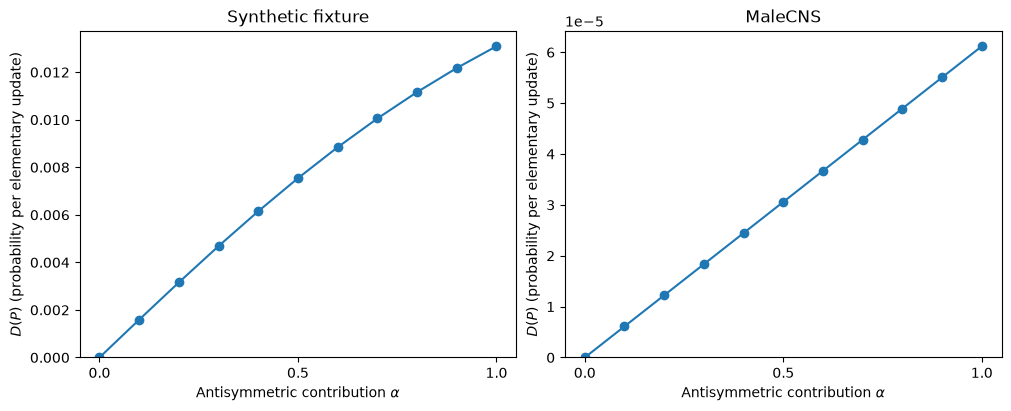

In [10]:
def split_coupling(J):
    """Split J into symmetric and antisymmetric parts."""
    S = 0.5 * (J + J.T)
    K = 0.5 * (J - J.T)
    return S, K


def gibbs_distribution(S, states, beta, gain, threshold, field):
    """Compute one Gibbs probability per configuration for symmetric S."""
    # Each row of states is a configuration sigma.
    # Summing (sigma @ S) * sigma gives sigma.T @ S @ sigma for that row.
    # The factor 1/2 accounts for counting each symmetric pair twice.
    pair_term = np.sum((states @ S) * states, axis=1)

    # Compute sum_i (h_i - theta_i) * x_i for each configuration.
    # NumPy broadcasts a scalar bias across all cells.
    bias = np.asarray(field) - np.asarray(threshold)
    field_term = np.sum(states * bias, axis=1)

    energy = -0.5 * gain * pair_term - field_term

    # A common shift in log weights cancels during normalization.
    # After shifting, the largest exponent is zero.
    log_weights = -beta * energy
    weights = np.exp(log_weights - log_weights.max())
    return weights / weights.sum()


S_toy, K_toy = split_coupling(J_toy)
S_malecns, K_malecns = split_coupling(J_malecns)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
alpha_tables = {}

for ax, name, J, S, K, states in [
    (axes[0], "Synthetic fixture", J_toy, S_toy, K_toy, states_toy),
    (axes[1], "MaleCNS", J_malecns, S_malecns, K_malecns, states_malecns),
]:
    # Check the decomposition before using it to change the dynamics.
    np.testing.assert_allclose(S, S.T, atol=ATOL, rtol=0)
    np.testing.assert_allclose(K, -K.T, atol=ATOL, rtol=0)
    np.testing.assert_allclose(S + K, J, atol=ATOL, rtol=RTOL)

    rows = []
    for alpha in ALPHAS:
        # Change only the antisymmetric contribution.
        # Independent row normalization could break the symmetry at alpha = 0.
        J_alpha = S + alpha * K
        P = transition_matrix(
            J_alpha, states, BETA, GAIN, THRESHOLD, REST_FIELD
        )
        pi = stationary_distribution(P)
        current = stationary_current(P, pi)

        stationarity_error = np.max(np.abs(pi @ P - pi))
        max_current = np.max(np.abs(current))

        if alpha == 0.0:
            # Compute pi independently from the symmetric energy.
            # Agreement checks the energy and the transition rule together.
            pi_gibbs = gibbs_distribution(
                S, states, BETA, GAIN, THRESHOLD, REST_FIELD
            )
            np.testing.assert_allclose(pi, pi_gibbs, atol=ATOL, rtol=RTOL)
            np.testing.assert_allclose(max_current, 0.0, atol=ATOL, rtol=0)

        rows.append({
            "alpha": alpha,
            "asymmetry_norm": np.linalg.norm(J_alpha - J_alpha.T),
            "coupling_norm": np.linalg.norm(J_alpha),
            "stationarity_residual": stationarity_error,
            "max_current": max_current,
        })

    results = pd.DataFrame(rows)
    alpha_tables[name] = results
    print(f"\n{name}")
    display(results)

    ax.plot(results["alpha"], results["max_current"], marker="o")
    ax.set_title(name)
    ax.set_xlabel(r"Antisymmetric contribution $\alpha$")
    ax.set_ylabel(r"$D(P)$ (probability per elementary update)")
    ax.set_xticks([0.0, 0.5, 1.0])
    ax.set_ylim(bottom=0)

plt.show()

## 6 · Show irreversibility using a cycle

There is an independent way to detect broken detailed balance using $P$ alone. In a reversible chain the products of transition probabilities along a closed cycle agree in both directions, because the ratios $\pi(\sigma')/\pi(\sigma)$ telescope. For a cycle $\sigma(0),\dots,\sigma(m)=\sigma(0)$ with positive probabilities in both directions, define its log ratio, also called the cycle affinity,
$$
\mathcal A=\sum_{r=0}^{m-1}\bigl[\log P(\sigma(r),\sigma(r+1))-\log P(\sigma(r+1),\sigma(r))\bigr].
$$
Finding one nonzero affinity disproves detailed balance. One zero affinity says only that this particular cycle passes the test. [Levin & Peres, §1.6](https://pages.uoregon.edu/dlevin/MARKOV/markovmixing.pdf)

**Exercise 6.** Implement `cycle_affinity(P, states, cycle)`. Fix the other cell states to zero. Start with two chosen coordinates $(\sigma_i,\sigma_j)=(0,0)$ and traverse $(0,0)\to(1,0)\to(1,1)\to(0,1)\to(0,0)$. Use the first two coordinates of the synthetic fixture and the first LPLC2 and DNp01 coordinates for MaleCNS. Check the two endpoints $\alpha=0$ and $\alpha=1$ and verify that reversing the loop flips the sign of the affinity. Report the result alongside the flux check.

**Written reasoning.** For a single-bit flip, zero self-coupling means the local field is identical on either end of the transition. What is the log forward/backward ratio for $0\to1$ at that site? Write all four contributions for the square. Which terms cancel? Use the resulting expression involving $J_{ij}$ and $J_{ji}$ to predict the measured sign for your choice of orientation.

In [11]:
def cycle_affinity(P, states, cycle):
    """Compute the log ratio of forward and reverse cycle probabilities."""
    state_to_index = {tuple(state): idx for idx, state in enumerate(states)}
    indices = [state_to_index[tuple(state)] for state in cycle]

    if len(indices) < 2 or indices[0] != indices[-1]:
        raise ValueError("The cycle must end at its starting state.")

    affinity = 0.0
    for source_index, target_index in zip(indices, indices[1:]):
        forward = P[source_index, target_index]
        backward = P[target_index, source_index]

        # The log ratio requires positive probabilities in both directions.
        # A step that flips more than one bit would fail this check.
        if forward <= 0 or backward <= 0:
            raise ValueError("Each step must be possible in both directions.")

        # Subtracting logs avoids forming a potentially extreme ratio.
        affinity += np.log(forward) - np.log(backward)

    return affinity


results = []

for name, J, states, i, j in [
    ("Synthetic fixture", J_toy, states_toy, 0, 1),  # 101 and 102
    ("MaleCNS", J_malecns, states_malecns, 0, 2),    # First LPLC2 and DNp01
]:
    S, K = split_coupling(J)

    # Visit the four corners in coordinates (i, j).
    # All other cells stay at zero throughout the cycle.
    cycle = []
    for bit_i, bit_j in [(0, 0), (1, 0), (1, 1), (0, 1), (0, 0)]:
        sigma = [0] * states.shape[1]
        sigma[i], sigma[j] = bit_i, bit_j
        cycle.append(tuple(sigma))

    print(f"{name}: {cycle}")

    for alpha in (0.0, 1.0):
        J_alpha = S + alpha * K
        P = transition_matrix(
            J_alpha, states, BETA, GAIN, THRESHOLD, REST_FIELD
        )

        forward_affinity = cycle_affinity(P, states, cycle)
        reverse_affinity = cycle_affinity(P, states, cycle[::-1])

        # Check the analytic result for this orientation of the square.
        predicted_affinity = BETA * GAIN * (J_alpha[j, i] - J_alpha[i, j])
        np.testing.assert_allclose(
            forward_affinity, predicted_affinity, atol=ATOL, rtol=RTOL
        )
        np.testing.assert_allclose(
            reverse_affinity, -forward_affinity, atol=ATOL, rtol=RTOL
        )

        # Compare the cycle diagnostic with the stationary current diagnostic.
        pi = stationary_distribution(P)
        current = stationary_current(P, pi)
        max_current = np.max(np.abs(current))

        if alpha == 0.0:
            np.testing.assert_allclose(forward_affinity, 0.0, atol=ATOL, rtol=0)
            np.testing.assert_allclose(max_current, 0.0, atol=ATOL, rtol=0)

        results.append({
            "network": name,
            "alpha": alpha,
            "forward_affinity": forward_affinity,
            "reverse_affinity": reverse_affinity,
            "predicted_affinity": predicted_affinity,
            "max_current": max_current,
        })

cycle_results = pd.DataFrame(results)
display(cycle_results)

Synthetic fixture: [(0, 0, 0), (1, 0, 0), (1, 1, 0), (0, 1, 0), (0, 0, 0)]
MaleCNS: [(0, 0, 0), (1, 0, 0), (1, 0, 1), (0, 0, 1), (0, 0, 0)]


,network,alpha,forward_affinity,reverse_affinity,predicted_affinity,max_current
0,Synthetic fixture,0.0,0.00000,0.00000,0.00000,3.122502e-17
1,Synthetic fixture,1.0,2.50000,-2.50000,2.50000,1.309130e-02
2,MaleCNS,0.0,0.00000,0.00000,0.00000,2.081668e-17
3,MaleCNS,1.0,0.00621,-0.00621,0.00621,6.118043e-05


**Your answer · Exercise 6**

*Write your derivation here.*

## 7 · Interpret the first result

Replace the placeholders below with compact explanations supported by your outputs.

1. **Anatomy → dynamics.** Pick one MaleCNS edge and trace it from the raw count to $J_{ij}$. Explain what the presynaptic sign and denominator each contribute. Which assumptions would you vary in a sensitivity analysis?
2. **Equilibrium → irreversibility.** Use the stationarity residual, $D(P)$, and the cycle affinity for the symmetric and directed cases. What does each tell you? Why can an irreversible chain still have a stationary distribution?
3. **Scope and next test.** What can you conclude about the specified three-cell model? How can missing neurons and uncertain signs affect its relevance to the full network? Which array becomes impractical as $N$ grows, and why?
4. **Bridge to the research question.** In the next experiment we will apply a weak field step to an input observable $B$ and measure a readout $O$. Under detailed balance the expected linear step response is
   $$
   \chi_{OB}(t)=\beta\left[C_{OB}(0)-C_{OB}(t)\right],
   \qquad C_{OB}(t)=\operatorname{Cov}_0\bigl[O(\sigma(t)),B(\sigma(0))\bigr].
   $$
   Describe in words the two measurements this formula lets us compare. What role will the verified $\alpha=0$ reference play when we test it? [Baiesi, Maes & Wynants (2009)](https://arxiv.org/abs/0902.3955)

**Your answer · Exercise 7**

1. Anatomy → dynamics
2. Equilibrium → irreversibility
3. Scope and next test
4. Bridge to the research question

## Reading order and submission

1. For the data, read the first results subsection and the STAR Methods subsections on segmentation, synapse identification and transmitter prediction. [Berg et al. (2026)](https://api.repository.cam.ac.uk/server/api/core/bitstreams/014024cf-3435-4a89-a5ed-bc34e2385772/content)
2. For exact probability calculations, read §1.6 on reversibility and §3.3.2 on single-site dynamics. These sections cover all the Markov-chain theory used in the assignment. [Levin & Peres, *Markov Chains and Mixing Times*](https://pages.uoregon.edu/dlevin/MARKOV/markovmixing.pdf)
3. For the next assignment, skim the introduction of the response paper and identify the role played by equilibrium time correlations. [Baiesi, Maes & Wynants (2009)](https://arxiv.org/abs/0902.3955)

Before submitting, restart the kernel and run the completed notebook top to bottom. Include your contact and coupling tables, kernel and Gibbs checks, the two-panel current figure, and the written interpretation. The next assignment will use the exact kernel to compare measured and covariance-predicted response. Subsequent work will test the same comparison with sampled trajectories and scale to larger MaleCNS networks.